### 1. TRỰC QUAN HÓA VÀ KHAI BÁO THƯ VIỆN:
#### Import các thư viện và thiết lập môi trường
Khởi tạo các thư viện cần thiết (`torch`, `torchvision`, `matplotlib`) và cấu hình đường dẫn `sys.path` để gọi các module trong `src/`.

In [5]:
import os
import sys
sys.path.insert(0, os.path.abspath('..'))

import torch
import torchvision
import matplotlib.pyplot as plt

from src.config import CLASS_NAMES, BATCH_SIZE
from src.preprocessing.dataset import get_fashion_mnist_datasets, get_data_loaders

print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")

PyTorch Version: 2.15.0+cpu
CUDA Available: False


### 2. CÀI ĐẶT TENSOR VÀ AUTOGRAD:
#### Khám phá Tensor & Cơ chế Autograd
Thử nghiệm khởi tạo Tensor 2D, tính toán một hàm số cơ bản $y = x^2 + 3x + 1$ và thực hiện lan truyền ngược (`backward()`) để tự động tính đạo hàm $\frac{dy}{dx}$.

In [6]:
# Tạo tensor có theo dõi đạo hàm
x = torch.tensor([[1.0, 2.0], [3.0, 4.0]], requires_grad=True)
print("Tensor x:\n", x)

# Tính toán hàm số y = x^2 + 3x + 1
y = x**2 + 3*x + 1
out = y.mean()

# Lan truyền ngược (Backpropagation)
out.backward()
print("\nĐạo hàm dy/dx:\n", x.grad)

Tensor x:
 tensor([[1., 2.],
        [3., 4.]], requires_grad=True)

Đạo hàm dy/dx:
 tensor([[1.2500, 1.7500],
        [2.2500, 2.7500]])


### 3. NẠP VÀ KIỂM TRA DATASET FASHIONMNIST:
#### Tải bộ dữ liệu FashionMNIST
Sử dụng hàm `get_fashion_mnist_datasets()` từ module `src.preprocessing.dataset` để tải tập dữ liệu Train/Test và kiểm tra các thông tin cấu trúc (Shape, Dtype, Label, Pixel values).

In [7]:
train_ds, test_ds = get_fashion_mnist_datasets()

print(f"Kích thước tập Train: {len(train_ds)}")
print(f"Kích thước tập Test: {len(test_ds)}")

img, label = train_ds[0]
print(f"\nShape của ảnh: {img.shape}")
print(f"Kiểu dữ liệu: {img.dtype}")
print(f"Nhãn: {label} -> Tên lớp: {CLASS_NAMES[label]}")
print(f"Giá trị Pixel tối thiểu: {img.min():.2f}, tối đa: {img.max():.2f}")

Kích thước tập Train: 60000
Kích thước tập Test: 10000

Shape của ảnh: torch.Size([1, 28, 28])
Kiểu dữ liệu: torch.float32
Nhãn: 9 -> Tên lớp: Ankle boot
Giá trị Pixel tối thiểu: -1.00, tối đa: 1.00


### 4. TRỰC QUAN HÓA ẢNH MẪU DATASET:
#### Trực quan hóa dữ liệu (Visualization)
Lấy một batch dữ liệu gồm 12 ảnh bằng `get_data_loaders()` và hiển thị danh sách các hình ảnh kèm nhãn tương ứng bằng `matplotlib`.

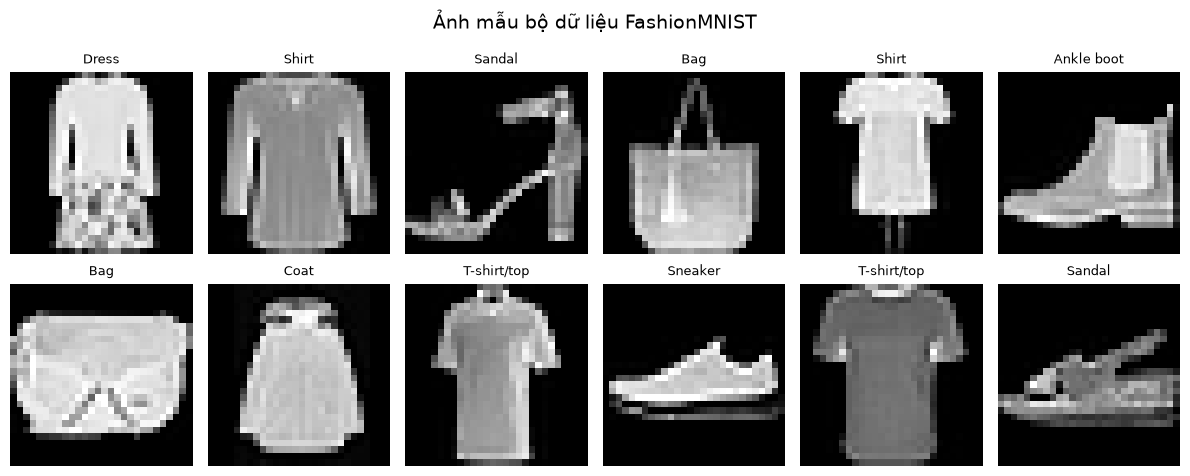

In [8]:
train_loader, _ = get_data_loaders(batch_size=12)
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 6, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap='gray')
    ax.set_title(CLASS_NAMES[labels[i]], fontsize=9)
    ax.axis('off')

plt.suptitle("Ảnh mẫu bộ dữ liệu FashionMNIST", fontsize=14)
plt.tight_layout()
plt.show()